## Attempt at using the linear regression using sklearn libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [89]:
df = pd.read_csv('data.csv')
df.head(10)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500
5,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,31200
6,BMW,1 Series,2012,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,26,17,3916,44100
7,BMW,1 Series,2012,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,39300
8,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,36900
9,BMW,1 Series,2013,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,27,18,3916,37200


## 3.1 Data Preparation  
* Change column headers to be consistent
* Remove spaces from string values e.g. Driven_Wheels, Model etc. Only applies to string fields
* Infill any missing values

In [45]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

In [46]:
df.columns = df.columns.str.lower().str.replace(' ','_')
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [47]:
categorical = df.dtypes[df.dtypes=='str'].index
numerical = df.dtypes[df.dtypes!='str'].index
for n in numerical:
    df[n]= df[n].fillna(0)

for c in categorical:
        df[c] = df[c].fillna('unkn')

In [48]:
#number of doors is really categorical
categorical = categorical.insert(len(categorical),'number_of_doors')
numerical = numerical.drop(['number_of_doors','msrp'])
categorical, numerical

(Index(['make', 'model', 'engine_fuel_type', 'transmission_type',
        'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style',
        'number_of_doors'],
       dtype='str'),
 Index(['year', 'engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg',
        'popularity'],
       dtype='str'))

In [49]:
df.number_of_doors = df.number_of_doors.astype(str)
#df[categorical].apply(lambda x : x.str.lower().str.replace(' ','_'))
for c in categorical:
    df[c] = df[c].str.lower().str.replace(' ' ,'_')


In [50]:
df.isnull().sum()

make                 0
model                0
year                 0
engine_fuel_type     0
engine_hp            0
engine_cylinders     0
transmission_type    0
driven_wheels        0
number_of_doors      0
market_category      0
vehicle_size         0
vehicle_style        0
highway_mpg          0
city_mpg             0
popularity           0
msrp                 0
dtype: int64

In [51]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors          str
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [52]:
df.groupby(by=['make','model'])['year'].agg(pd.Series.mode)

make   model     
acura  cl                    2003
       ilx           [2016, 2017]
       ilx_hybrid            2014
       integra               2001
       legend                1995
                         ...     
volvo  v90                   1998
       xc                    2002
       xc60                  2015
       xc70                  2016
       xc90                  2016
Name: year, Length: 828, dtype: object

In [53]:
df.groupby(by=['make','model'])['year'].agg(lambda x: x.mode().iloc[0])

make   model     
acura  cl            2003
       ilx           2016
       ilx_hybrid    2014
       integra       2001
       legend        1995
                     ... 
volvo  v90           1998
       xc            2002
       xc60          2015
       xc70          2016
       xc90          2016
Name: year, Length: 828, dtype: int64

<Axes: xlabel='msrp', ylabel='Count'>

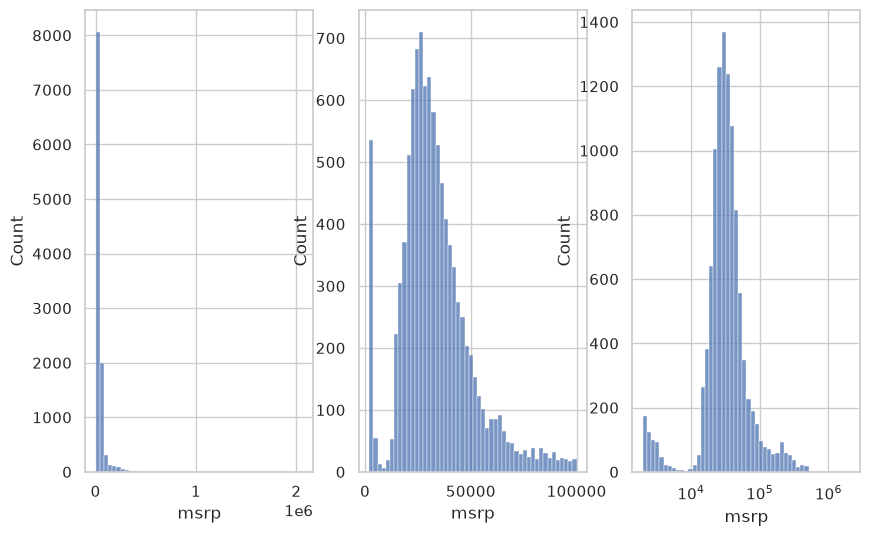

In [54]:
fix, ax = plt.subplots(1,3,figsize=(10,6))
sns.histplot(df.msrp, bins=50, ax=ax[0])
sns.histplot(df[df['msrp']<100000].msrp, bins=50, ax=ax[1])
sns.histplot(df.msrp, log_scale=True,bins=50, ax=ax[2])

### Feature engineering

In [55]:
#generate age feature
df['age'] = 2017 - df.year
numerical = numerical.insert(len(numerical),'age')
numerical

Index(['year', 'engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg',
       'popularity', 'age'],
      dtype='str')

In [56]:
other_makes = ['tesla', 'hummer', 'maybach', 'alfa_romeo', 'mclaren', 'spyker', 'genesis', 'bugatti']
df['make_bin'] = df.make.replace(other_makes,'other')
df.make_bin.value_counts()

categorical
categorical = categorical.drop(['make'])
categorical = categorical.insert(0,'make_bin')

## 3.2 Set up validation framework

In [57]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df,test_size=0.2,random_state=1)
df_train, df_val  = train_test_split(df_full_train,test_size=0.25,random_state=1)
len(df), len(df_full_train), len(df_train), len(df_val), len(df_test)

(10878, 8702, 6526, 2176, 2176)

In [58]:
df_test.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_train.reset_index(drop=True, inplace=True)
df_full_train.reset_index(drop=True, inplace=True)

In [59]:
y_test = np.log1p(df_test.msrp).values
y_val = np.log1p(df_val.msrp).values
y_train = np.log1p(df_train.msrp).values
y_full_train = np.log1p(df_full_train.msrp).values

#del df_test['msrp']
#del df_val['msrp']
#del df_full_train['msrp']
#del df_train['msrp']

## 3.3 Correlation and Mutual Info  

In [60]:
df_full_train[numerical].corrwith(df_full_train.msrp)
#only engine_hp and engine_cyclinders show strong correlation

year                0.125596
engine_hp           0.636928
engine_cylinders    0.537903
highway_mpg        -0.179979
city_mpg           -0.174105
popularity         -0.061071
age                -0.125596
dtype: float64

### Mutual Info

In [61]:
from sklearn.metrics import mutual_info_score

def mutual_info_mspr_score(series):
    return mutual_info_score(df_full_train.msrp, series)

mi = df_full_train[categorical].apply(mutual_info_mspr_score)
mi.sort_values(ascending=False)

model                5.721791
make_bin             2.930176
market_category      2.421535
vehicle_style        1.815946
driven_wheels        1.026026
engine_fuel_type     1.002299
vehicle_size         0.821016
transmission_type    0.591232
number_of_doors      0.518061
dtype: float64

<Axes: >

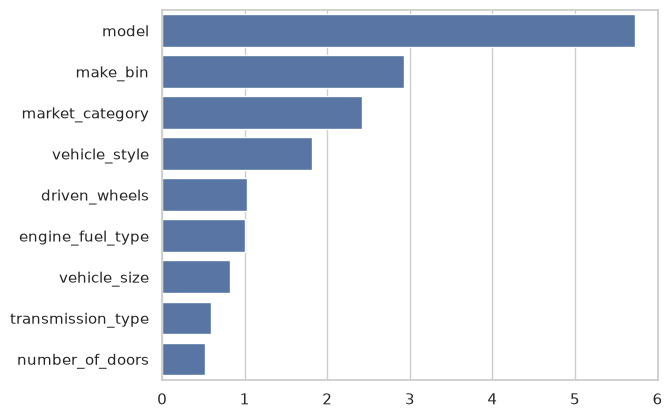

In [62]:
import seaborn as sns
sns.barplot(mi,order=list(mi.sort_values(ascending=False).index), orient='h')

So from correlation and Mutual Info the following features should be used:
* model
* make
* market_category -this is not a good choice since it is free text
* vehicle_style
* age

In [63]:
feats_cat = ['make_bin']
feats_num = ['age','engine_hp','engine_cylinders']
feats_all = ['make_bin','age','engine_hp','engine_cylinders']

## 3.6 OHE

Does this on the training data

In [64]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False)
X_train_cat = ohe.fit_transform(df_train[feats_cat])
X_train_cat.shape

(6526, 41)

In [65]:
X_train_num = df_train[feats_num].values
X_train = np.column_stack([X_train_num,X_train_cat])
X_train.shape

(6526, 44)

In [66]:
X_val_num = df_val[feats_num].values
X_val_cat = ohe.transform(df_val[feats_cat])
X_val = np.column_stack([X_val_num,X_val_cat])
X_val.shape

(2176, 44)

## 3.7 Fit model

In [67]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

In [68]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](44,)","[-0.07, 0. , 0.05,...,-0.46,-0.2 ,-0.22]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,10.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,44
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(43)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](44,)","[8737.96, 447.52, 77.57,..., 3.94, 3.02, 0. ]"


In [69]:
np.expm1(model.intercept_)

np.float64(22415.36547126558)

In [70]:
model.coef_

array([-0.0729535 ,  0.00241635,  0.04810164, -0.1418173 ,  0.72987296,
        0.02754379,  0.89972316,  0.01471493, -0.16416191, -0.01719485,
       -0.33667986, -0.19672079, -0.38195235,  1.36502864, -0.42264242,
       -0.39221059, -0.30209473, -0.37686971, -0.41203403, -0.05915611,
       -0.39790077,  0.87488587,  0.26363197, -0.00457881,  0.03109351,
        0.66126204,  0.52199606, -0.26114425, -0.08898765, -0.21891137,
       -0.47294616, -0.02987365,  0.89829989, -1.51237647,  0.06493673,
        0.23938321,  1.28417185,  0.09704482, -0.47388785, -0.30917088,
       -0.11750402, -0.46045884, -0.20411011, -0.21820395])

In [71]:
np.array(feats_num), np.array(ohe.get_feature_names_out())

(array(['age', 'engine_hp', 'engine_cylinders'], dtype='<U16'),
 array(['make_bin_acura', 'make_bin_aston_martin', 'make_bin_audi',
        'make_bin_bentley', 'make_bin_bmw', 'make_bin_buick',
        'make_bin_cadillac', 'make_bin_chevrolet', 'make_bin_chrysler',
        'make_bin_dodge', 'make_bin_ferrari', 'make_bin_fiat',
        'make_bin_ford', 'make_bin_gmc', 'make_bin_honda',
        'make_bin_hyundai', 'make_bin_infiniti', 'make_bin_kia',
        'make_bin_lamborghini', 'make_bin_land_rover', 'make_bin_lexus',
        'make_bin_lincoln', 'make_bin_lotus', 'make_bin_maserati',
        'make_bin_mazda', 'make_bin_mercedes-benz', 'make_bin_mitsubishi',
        'make_bin_nissan', 'make_bin_oldsmobile', 'make_bin_other',
        'make_bin_plymouth', 'make_bin_pontiac', 'make_bin_porsche',
        'make_bin_rolls-royce', 'make_bin_saab', 'make_bin_scion',
        'make_bin_subaru', 'make_bin_suzuki', 'make_bin_toyota',
        'make_bin_volkswagen', 'make_bin_volvo'], dtype=object)

In [72]:
dict(zip(np.append(np.array(feats_num),np.array(ohe.get_feature_names_out())), model.coef_))

{'age': np.float64(-0.07295350264437778),
 'engine_hp': np.float64(0.002416346392331572),
 'engine_cylinders': np.float64(0.048101636046863586),
 'make_bin_acura': np.float64(-0.14181729711525376),
 'make_bin_aston_martin': np.float64(0.7298729603726694),
 'make_bin_audi': np.float64(0.02754379420708299),
 'make_bin_bentley': np.float64(0.8997231599671096),
 'make_bin_bmw': np.float64(0.014714925210913651),
 'make_bin_buick': np.float64(-0.16416190792741642),
 'make_bin_cadillac': np.float64(-0.01719484667059609),
 'make_bin_chevrolet': np.float64(-0.3366798603331931),
 'make_bin_chrysler': np.float64(-0.19672078602467752),
 'make_bin_dodge': np.float64(-0.38195235406142036),
 'make_bin_ferrari': np.float64(1.36502864042465),
 'make_bin_fiat': np.float64(-0.42264241683932674),
 'make_bin_ford': np.float64(-0.39221059313433754),
 'make_bin_gmc': np.float64(-0.30209472763833783),
 'make_bin_honda': np.float64(-0.3768697092652972),
 'make_bin_hyundai': np.float64(-0.4120340297164152),
 'm

## 3.8 Predict Model

In [73]:
y_train_pred = model.predict(X_train)

<Axes: ylabel='Count'>

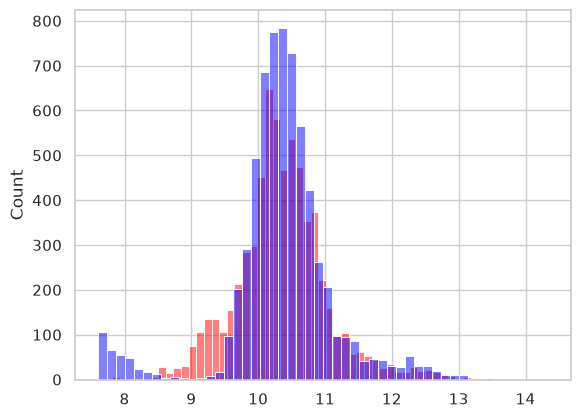

In [74]:
sns.histplot(y_train_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [75]:
y_val_pred = model.predict(X_val)

<Axes: ylabel='Count'>

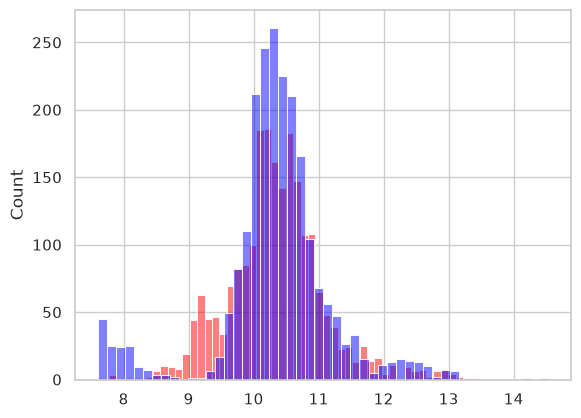

In [76]:
sns.histplot(y_val_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50)

In [77]:
y_train.shape, y_val.shape

((6526,), (2176,))

In [78]:
df_res = pd.DataFrame(y_train)
df_res['pred'] = y_train_pred
df_res.columns = ['obs','pred']
df_res['residual'] = df_res.obs-df_res.pred
df_res['pred_index'] = range(0,len(df_res))

In [79]:
df_res.reset_index(drop=False)
df_res
#sns.scatterplot(data=df_res[['residual','pred_index']],y='pred_index')

,obs,pred,residual,pred_index
0,10.655752,10.141841,0.513912,0
1,9.918425,10.133776,-0.215350,1
2,12.458437,12.833561,-0.375124,2
3,10.961295,10.907601,0.053694,3
4,7.617760,8.614722,-0.996962,4
...,...,...,...,...
6521,10.561940,10.575652,-0.013712,6521
6522,11.083388,10.789575,0.293813,6522
6523,10.554927,11.223187,-0.668260,6523
6524,10.578496,10.658135,-0.079639,6524


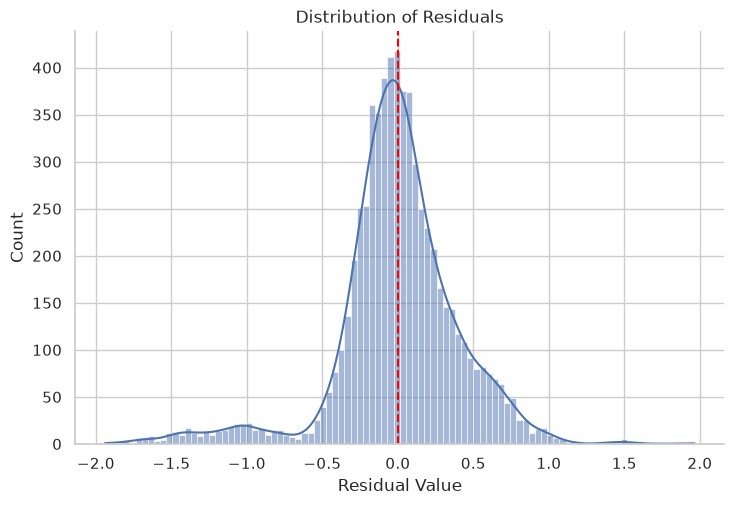

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot the distribution of residuals
sns.displot(data=df_res, x="residual", kde=True, height=5, aspect=1.5)

# Add a vertical reference line at 0 (where perfect predictions sit)
plt.axvline(x=0, color="red", linestyle="--", linewidth=1.5)

plt.title("Distribution of Residuals")
plt.xlabel("Residual Value")
plt.show()


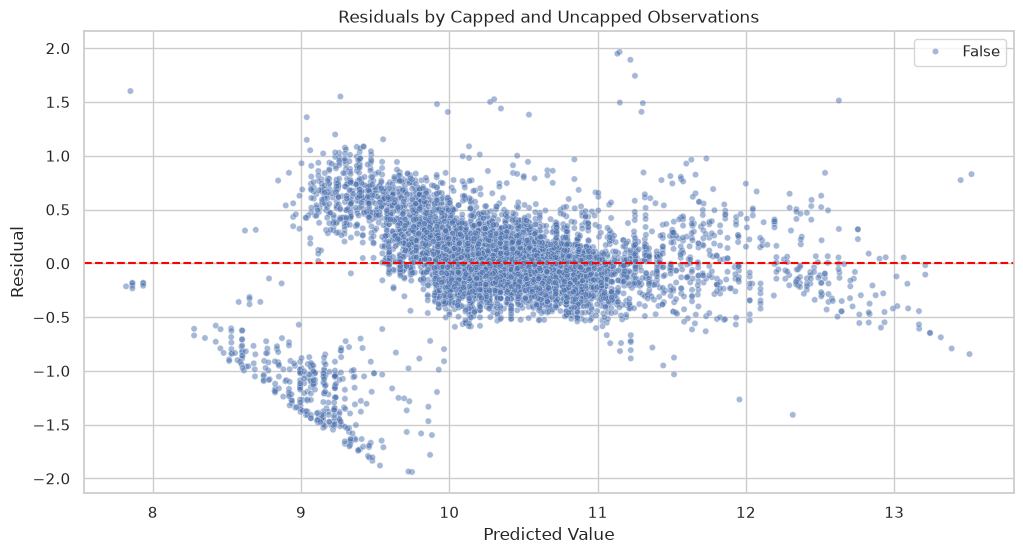

In [81]:
cap = np.log1p(2000)
df_res['capped'] =  np.isclose(df_res['obs'], cap)
df_res.capped.sum()

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_res,
    x='pred',
    y='residual',
    hue='capped',
    alpha=0.5,
    s=20
)

plt.axhline(0, color='red', linestyle='--')

x = np.linspace(df_res.pred.min(),
                df_res.pred.max(), 100)

plt.xlabel('Predicted Value')
plt.ylabel('Residual')
plt.title('Residuals by Capped and Uncapped Observations')
plt.legend()
plt.show()

In [40]:
np.expm1(df_res.obs.min())

np.float64(2000.0)

In [90]:
cap = np.log1p(2000)
df_res['capped'] =  np.isclose(df_res['obs'], cap)
df_res.capped.sum()

np.int64(625)

In [88]:
df_res[df_res.obs==np.log1p(2000)]['obs'].astype('int')

18      7
26      7
36      7
52      7
53      7
       ..
7072    7
7091    7
7097    7
7139    7
7146    7
Name: obs, Length: 625, dtype: int64

In [82]:
y_full

NameError: name 'y_full' is not defined

<Axes: xlabel='MSRP', ylabel='Count'>

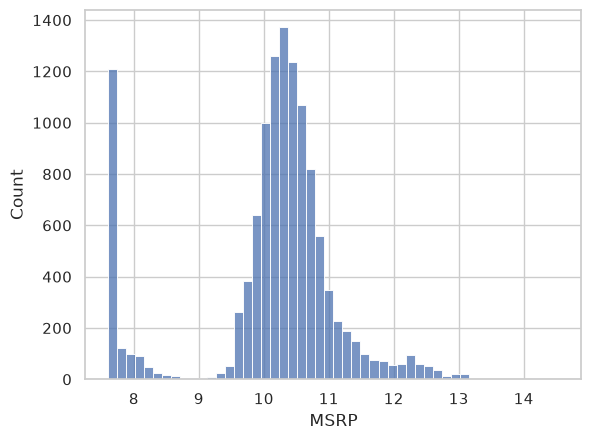

In [91]:
ms = np.log1p(df.MSRP)
sns.histplot(data=ms, bins=50)